In [1]:

!pip install -q numpy pandas matplotlib seaborn scikit-learn


In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

print("All libraries imported successfully!")


All libraries imported successfully!


In [5]:
from google.colab import files

uploaded = files.upload()

Saving creditcard.csv to creditcard.csv


In [6]:

import pandas as pd

# Load the dataset
df = pd.read_csv("creditcard.csv")

# Display basic information
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

# Display first 5 records
df.head()


Dataset loaded successfully!
Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [7]:

# 1. Display all column names
print("COLUMN NAMES:")
print(df.columns.tolist())

# 2. Check dataset information
print("\nDATASET INFORMATION:")
df.info()

# 3. Check missing values
print("\nTOTAL MISSING VALUES:")
print(df.isnull().sum().sum())

# 4. Check duplicate records
print("\nTOTAL DUPLICATE RECORDS:")
print(df.duplicated().sum())


COLUMN NAMES:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

DATASET INFORMATION:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  

In [8]:

# Check original dataset size
print("Before cleaning:", df.shape)

# Remove duplicate records
df = df.drop_duplicates()

# Check dataset after cleaning
print("After cleaning:", df.shape)

# Count removed records
print("Duplicates removed:", 1081)

# Check missing values again
print("Missing values:", df.isnull().sum().sum())


Before cleaning: (284807, 31)
After cleaning: (283726, 31)
Duplicates removed: 1081
Missing values: 0


Transaction Distribution:
Class
0    283253
1       473
Name: count, dtype: int64


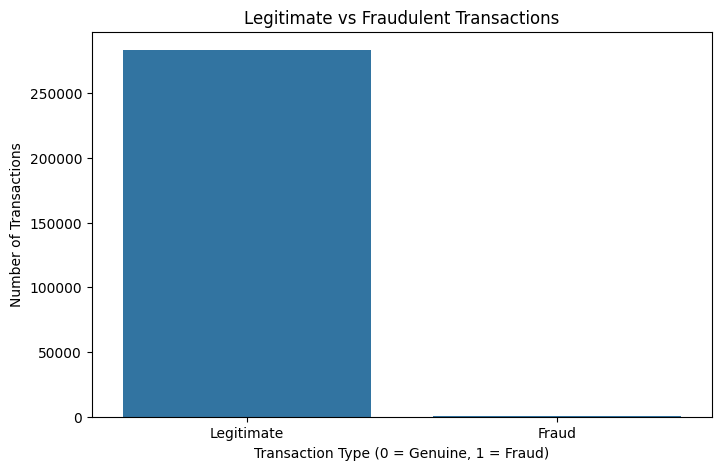

In [9]:

# Count transaction types
print("Transaction Distribution:")
print(df["Class"].value_counts())

# Create a graph
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Class")

plt.title("Legitimate vs Fraudulent Transactions")
plt.xlabel("Transaction Type (0 = Genuine, 1 = Fraud)")
plt.ylabel("Number of Transactions")

plt.xticks([0, 1], ["Legitimate", "Fraud"])
plt.show()


Top 10 features correlated with fraud:
V17   -0.313498
V14   -0.293375
V12   -0.250711
V10   -0.206971
V16   -0.187186
V3    -0.182322
V7    -0.172347
V11    0.149067
V4     0.129326
V18   -0.105340
Name: Class, dtype: float64


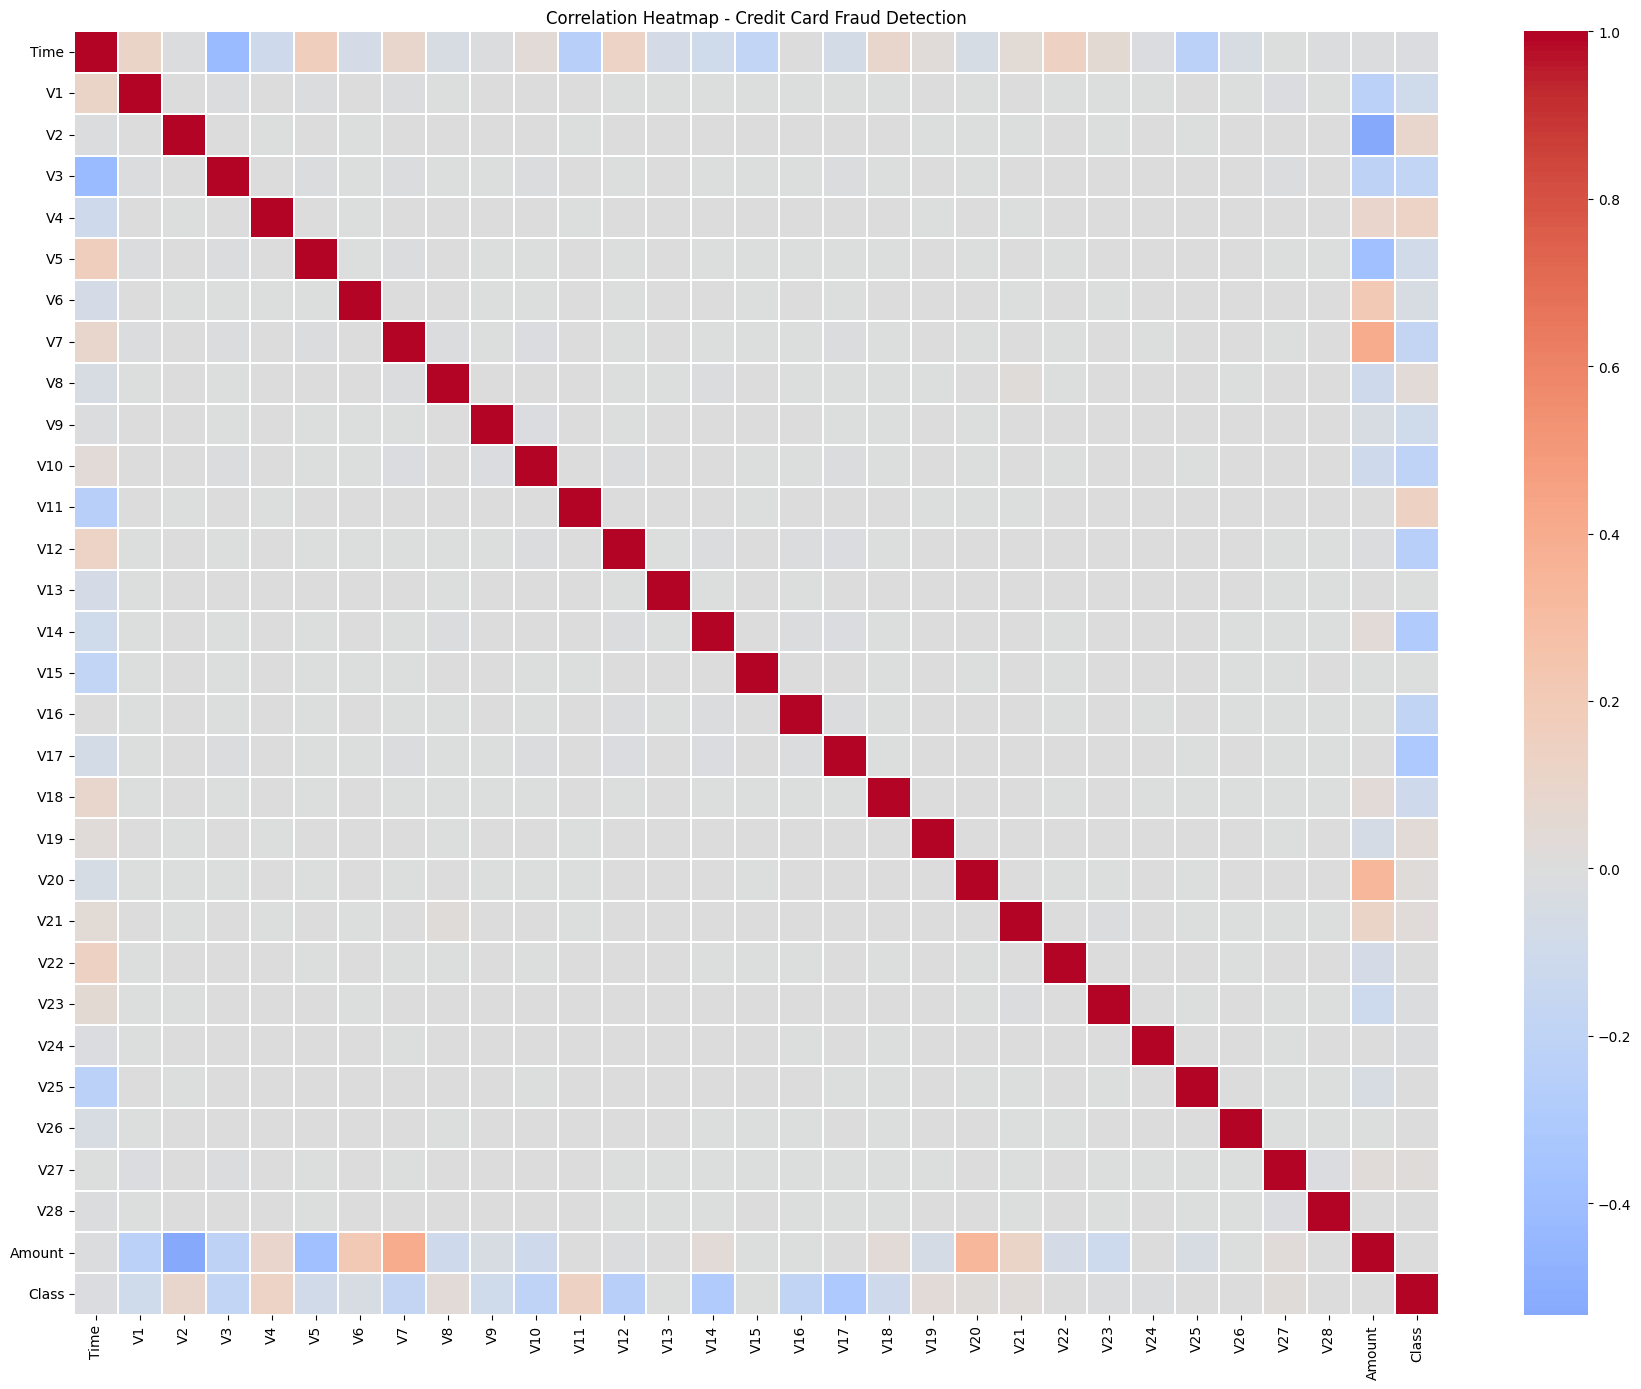

In [10]:

# Calculate correlation between all numerical columns
correlation_matrix = df.corr(numeric_only=True)

# Display correlation with fraud (Class)
fraud_correlation = correlation_matrix["Class"].drop("Class")

# Sort by strongest absolute correlation
fraud_correlation = fraud_correlation.reindex(
    fraud_correlation.abs().sort_values(ascending=False).index
)

print("Top 10 features correlated with fraud:")
print(fraud_correlation.head(10))

# Create correlation heatmap
plt.figure(figsize=(18, 14))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.1
)

plt.title("Correlation Heatmap - Credit Card Fraud Detection")
plt.tight_layout()
plt.show()


In [11]:

# Separate input features and target
X = df.drop("Class", axis=1)
y = df["Class"]

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("Training fraud cases:", y_train.sum())
print("Testing fraud cases:", y_test.sum())


Training data: (226980, 30)
Testing data: (56746, 30)
Training fraud cases: 378
Testing fraud cases: 95


In [12]:

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Logistic Regression preprocessing
lr_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Random Forest preprocessing
rf_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

print("Preprocessing pipelines created successfully!")


Preprocessing pipelines created successfully!


In [13]:

# Create Logistic Regression model
logistic_model = Pipeline([
    ("preprocessing", lr_preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train model
logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed!")


Logistic Regression training completed!


In [14]:

# Create Random Forest model
random_forest_model = Pipeline([
    ("preprocessing", rf_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=150,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

# Train model
random_forest_model.fit(X_train, y_train)

print("Random Forest training completed!")


Random Forest training completed!


In [15]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model
}

results = []
predictions = {}
probabilities = {}

for name, model in models.items():

    # Predict transaction classes
    y_pred = model.predict(X_test)

    # Predict fraud probabilities
    y_prob = model.predict_proba(X_test)[:, 1]

    predictions[name] = y_pred
    probabilities[name] = y_prob

    # Calculate evaluation metrics
    results.append({
        "Model": name,
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC AUC": roc_auc_score(y_test, y_prob)
    })

# Display comparison
results_df = pd.DataFrame(results)

display(results_df.round(4))


,Model,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.0564,0.8737,0.1059,0.9657
1,Random Forest,0.9853,0.7053,0.8221,0.9292


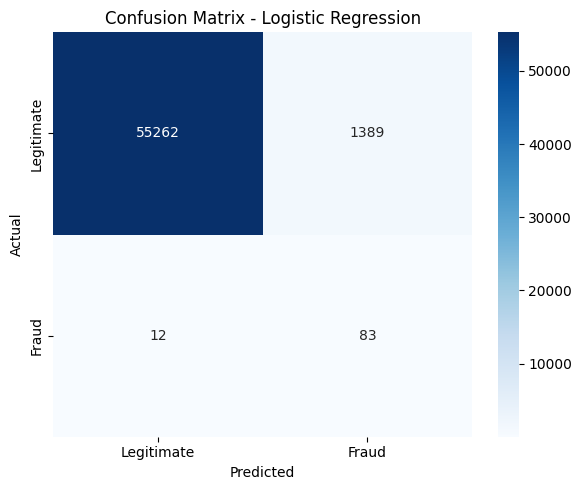


Classification Report: Logistic Regression
              precision    recall  f1-score   support

  Legitimate       1.00      0.98      0.99     56651
       Fraud       0.06      0.87      0.11        95

    accuracy                           0.98     56746
   macro avg       0.53      0.92      0.55     56746
weighted avg       1.00      0.98      0.99     56746



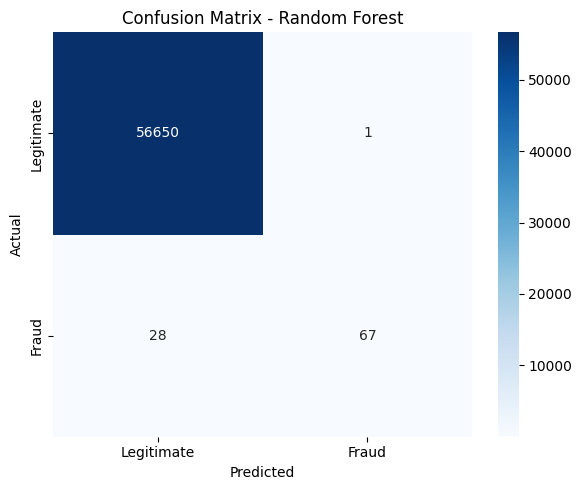


Classification Report: Random Forest
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56651
       Fraud       0.99      0.71      0.82        95

    accuracy                           1.00     56746
   macro avg       0.99      0.85      0.91     56746
weighted avg       1.00      1.00      1.00     56746



In [16]:

for name, y_pred in predictions.items():

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Legitimate", "Fraud"],
        yticklabels=["Legitimate", "Fraud"]
    )

    plt.title("Confusion Matrix - " + name)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.tight_layout()
    plt.savefig(
        name.replace(" ", "_").lower() + "_confusion_matrix.png",
        dpi=150
    )
    plt.show()

    print("\nClassification Report:", name)
    print(classification_report(
        y_test,
        y_pred,
        target_names=["Legitimate", "Fraud"],
        zero_division=0
    ))


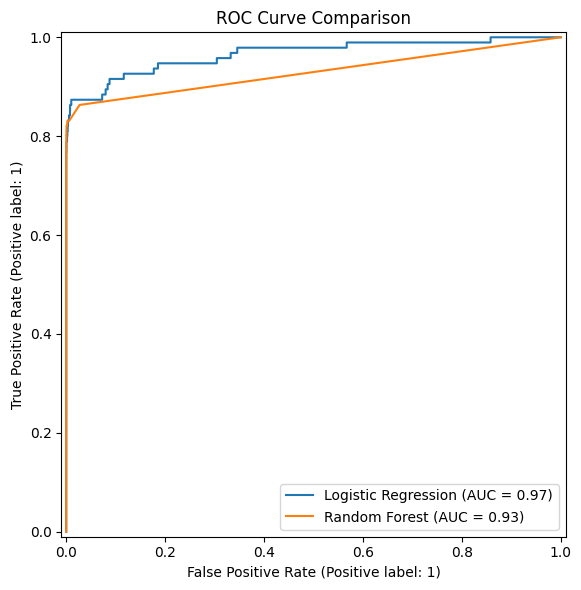

In [17]:

from sklearn.metrics import RocCurveDisplay

plt.figure(figsize=(8, 6))

ax = plt.gca()

for name, model in models.items():
    RocCurveDisplay.from_estimator(
        model,
        X_test,
        y_test,
        name=name,
        ax=ax
    )

plt.title("ROC Curve Comparison")
plt.tight_layout()
plt.savefig("roc_curve_comparison.png", dpi=150)
plt.show()


In [18]:

import joblib

# Select model with the higher test F1 score
best_model_name = results_df.loc[
    results_df["F1 Score"].idxmax(), "Model"
]

best_model = models[best_model_name]

# Save model
joblib.dump(best_model, "fraud_detection_model.joblib")

# Save comparison results
results_df.to_csv(
    "model_comparison_results.csv",
    index=False
)

print("Selected model:", best_model_name)
print("Model saved successfully!")
print("Comparison results saved successfully!")


Selected model: Random Forest
Model saved successfully!
Comparison results saved successfully!


In [19]:

# Select one transaction from test data
sample = X_test.iloc[[0]]

# Predict transaction
prediction = best_model.predict(sample)[0]

# Get fraud probability
probability = best_model.predict_proba(sample)[0][1]

print("Prediction:", "FRAUD" if prediction == 1 else "LEGITIMATE")
print("Fraud probability:", round(probability * 100, 2), "%")


Prediction: LEGITIMATE
Fraud probability: 0.0 %


In [20]:

readme = """
# Credit Card Fraud Detection Using Machine Learning

## Project Overview
This project uses machine learning to identify potentially
fraudulent credit card transactions.

## Dataset
Source: Kaggle Credit Card Fraud Detection
https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud

## Technologies
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Google Colab

## Project Workflow
1. Dataset collection
2. Data inspection
3. Missing value analysis
4. Duplicate removal
5. Exploratory Data Analysis
6. Correlation analysis
7. Training and testing split
8. Logistic Regression training
9. Random Forest training
10. Model evaluation

## Evaluation Metrics
- Precision
- Recall
- F1 Score
- ROC-AUC
- Confusion Matrix

## Models
- Logistic Regression
- Random Forest

## Execution
Open the notebook in Google Colab.
Download the Kaggle dataset and upload creditcard.csv
when prompted. Run the cells in order.

## Important
This is an academic machine learning project.
It is not a production banking fraud detection system.
"""

with open("README.md", "w") as f:
    f.write(readme)

with open("requirements.txt", "w") as f:
    f.write(
        "numpy\npandas\nmatplotlib\nseaborn\n"
        "scikit-learn\njoblib\n"
    )

with open(".gitignore", "w") as f:
    f.write(
        "creditcard.csv\n*.zip\n__pycache__/\n"
        ".ipynb_checkpoints/\n"
    )

print("Documentation files created!")


Documentation files created!


In [22]:

from google.colab import files

files.download("model_comparison_results.csv")
files.download("fraud_detection_model.joblib")
files.download("README.md")
files.download("requirements.txt")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>